# Character-Level Name Generator

### Setup and Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

import torch
from torch.utils.data import DataLoader, random_split
from torch import nn

# Use CPU for this notebook to avoid CUDA issues
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using {device} device")

Using cpu device


### Load Dataset

In [4]:
names = pd.read_csv(r'sample_data/names.txt', names=['Names'])
names.head()

,Names
0,aarav
1,aarush
2,aditya
3,akash
4,aman


### Character Mappings

In [29]:
all_chars = ''.join(names['Names']).replace(' ', '')
unique_chars = ['<PAD>'] + sorted(list(set(all_chars))) + ['<EOS>'] # Add <EOS> token

char_to_idx = {}
idx_to_char = {}

char_to_idx.update({char: i for i, char in enumerate(unique_chars)})
idx_to_char.update({i: char for i, char in enumerate(unique_chars)})

# For generation, we'll use characters excluding <PAD> and <EOS>
unique_chars_for_gen = [char for char in unique_chars if char != '<PAD>' and char != '<EOS>']

print("Character to Index mapping:")
print(char_to_idx)
print("\nIndex to Character mapping:")
print(idx_to_char)
print(f"\nCharacters for generation: {unique_chars_for_gen}")

Character to Index mapping:
{'<PAD>': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'r': 17, 's': 18, 't': 19, 'u': 20, 'v': 21, 'w': 22, 'x': 23, 'y': 24, '<EOS>': 25}

Index to Character mapping:
{0: '<PAD>', 1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'r', 18: 's', 19: 't', 20: 'u', 21: 'v', 22: 'w', 23: 'x', 24: 'y', 25: '<EOS>'}

Characters for generation: ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y']


### Encode Names with EOS Token

In [6]:
encoded_list = []

for name in names.Names:
  chars = [char_to_idx[x] for x in name if x != ' '] + [char_to_idx['<EOS>']] # Append <EOS> token
  encoded_list.append(chars)

print(encoded_list)

[[1, 1, 17, 1, 21, 25], [1, 1, 17, 20, 18, 8, 25], [1, 4, 9, 19, 24, 1, 25], [1, 11, 1, 18, 8, 25], [1, 13, 1, 14, 25], [1, 14, 9, 11, 5, 19, 25], [1, 17, 10, 20, 14, 25], [1, 17, 24, 1, 14, 25], [1, 19, 8, 1, 17, 21, 1, 25], [1, 24, 20, 18, 8, 25], [2, 8, 1, 21, 5, 18, 8, 25], [2, 8, 1, 17, 1, 19, 25], [3, 8, 9, 17, 1, 7, 25], [4, 1, 17, 18, 8, 1, 14, 25], [4, 5, 5, 16, 1, 11, 25], [7, 1, 20, 17, 1, 21, 25], [8, 1, 17, 18, 8, 25], [8, 1, 17, 18, 8, 9, 19, 25], [9, 18, 8, 1, 1, 14, 25], [10, 1, 24, 25], [10, 1, 19, 9, 14, 25], [11, 1, 17, 1, 14, 25], [11, 1, 17, 19, 9, 11, 25], [11, 17, 9, 18, 8, 14, 1, 25], [12, 1, 11, 18, 8, 25], [12, 15, 11, 5, 18, 8, 25], [13, 1, 14, 1, 21, 25], [13, 1, 24, 20, 17, 25], [13, 15, 8, 9, 19, 25], [14, 1, 11, 20, 12, 25], [14, 9, 11, 8, 9, 12, 25], [15, 13, 11, 1, 17, 25], [16, 1, 17, 19, 8, 25], [16, 17, 1, 14, 1, 21, 25], [16, 17, 1, 19, 9, 11, 25], [17, 1, 8, 20, 12, 25], [17, 1, 10, 25], [17, 15, 8, 1, 14, 25], [17, 15, 8, 9, 19, 25], [18, 1, 7, 1,

### Visualize Name Parsing (Original)

In [7]:
for name in names['Names'][:5]:
  curr_char = ''
  for char, next_char in zip(name, name[1:]): # 'curr_char' : input, 'next_char' : target
    curr_char += char
    print(f"{curr_char} -> {next_char}")
  print()

a -> a
aa -> r
aar -> a
aara -> v

a -> a
aa -> r
aar -> u
aaru -> s
aarus -> h

a -> d
ad -> i
adi -> t
adit -> y
adity -> a

a -> k
ak -> a
aka -> s
akas -> h

a -> m
am -> a
ama -> n



In [8]:
train_samples = []

# Adjust to handle <EOS> token
for x in encoded_list:
    for i in range(len(x) - 1):
        input_seq = x[:i+1]
        target = x[i+1] # Target is the next character, including <EOS>

        train_samples.append((input_seq, target))

print(train_samples)

[([1], 1), ([1, 1], 17), ([1, 1, 17], 1), ([1, 1, 17, 1], 21), ([1, 1, 17, 1, 21], 25), ([1], 1), ([1, 1], 17), ([1, 1, 17], 20), ([1, 1, 17, 20], 18), ([1, 1, 17, 20, 18], 8), ([1, 1, 17, 20, 18, 8], 25), ([1], 4), ([1, 4], 9), ([1, 4, 9], 19), ([1, 4, 9, 19], 24), ([1, 4, 9, 19, 24], 1), ([1, 4, 9, 19, 24, 1], 25), ([1], 11), ([1, 11], 1), ([1, 11, 1], 18), ([1, 11, 1, 18], 8), ([1, 11, 1, 18, 8], 25), ([1], 13), ([1, 13], 1), ([1, 13, 1], 14), ([1, 13, 1, 14], 25), ([1], 14), ([1, 14], 9), ([1, 14, 9], 11), ([1, 14, 9, 11], 5), ([1, 14, 9, 11, 5], 19), ([1, 14, 9, 11, 5, 19], 25), ([1], 17), ([1, 17], 10), ([1, 17, 10], 20), ([1, 17, 10, 20], 14), ([1, 17, 10, 20, 14], 25), ([1], 17), ([1, 17], 24), ([1, 17, 24], 1), ([1, 17, 24, 1], 14), ([1, 17, 24, 1, 14], 25), ([1], 19), ([1, 19], 8), ([1, 19, 8], 1), ([1, 19, 8, 1], 17), ([1, 19, 8, 1, 17], 21), ([1, 19, 8, 1, 17, 21], 1), ([1, 19, 8, 1, 17, 21, 1], 25), ([1], 24), ([1, 24], 20), ([1, 24, 20], 18), ([1, 24, 20, 18], 8), ([1, 24

### Define DataFrame Separate Features and Targets

In [9]:
names_data = pd.DataFrame(train_samples, columns=['input', 'target'])
display(names_data.head())
print(names_data.shape)

,input,target
0,[1],1
1,"[1, 1]",17
2,"[1, 1, 17]",1
3,"[1, 1, 17, 1]",21
4,"[1, 1, 17, 1, 21]",25


(2989, 2)


In [10]:
X = names_data['input']
y = names_data['target']

display(X[:5], y[:5])
print(X.shape, y.shape)

,input
0,[1]
1,"[1, 1]"
2,"[1, 1, 17]"
3,"[1, 1, 17, 1]"
4,"[1, 1, 17, 1, 21]"


,target
0,1
1,17
2,1
3,21
4,25


(2989,) (2989,)


### Define Custom Dataset

In [11]:
max_len = 0
for i in range(len(X)):
  max_len = max(max_len, len(X[i]))

print(max_len)

10


In [12]:
x_tensor = torch.zeros(len(X), max_len, dtype=torch.long)
for i, row in enumerate(X):
  x_tensor[i, :len(row)] = torch.tensor(row)

y_tensor = torch.tensor(y, dtype=torch.long)

print(f"X shape: {x_tensor.shape}\nY shape: {y_tensor.shape}")

X shape: torch.Size([2989, 10])
Y shape: torch.Size([2989])


In [13]:
from torch.utils.data import Dataset

class NameDataset(Dataset):
    def __init__(self, x_tensor, y_tensor):
        self.x_data = x_tensor
        self.y_data = y_tensor

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        return self.x_data[idx], self.y_data[idx]

dataset = NameDataset(x_tensor, y_tensor)
print(f"Dataset size: {len(dataset)}")

input_seq, target = dataset[4]
print(f"First sample input: {input_seq}, target: {target}")

Dataset size: 2989
First sample input: tensor([ 1,  1, 17,  1, 21,  0,  0,  0,  0,  0]), target: 25


### Train & Test DataLoader

In [14]:
train_data, test_data = random_split(dataset=dataset, lengths=[0.7, 0.3])

train_dataloader = DataLoader(dataset=train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(dataset=test_data, batch_size=64, shuffle=False)

# Example of iterating through one batch
for input_batch, target_batch in train_dataloader:
    print(f"Input batch shape: {input_batch.shape}")
    print(f"Target batch shape: {target_batch.shape}")
    break # Just print the first batch to verify

Input batch shape: torch.Size([64, 10])
Target batch shape: torch.Size([64])


### Define CharLSTM Model

In [34]:
vocab_size = len(idx_to_char)

class CharLSTM(nn.Module):
  def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers=1, dropout_prob=0.5):
     super().__init__()
     # Explicitly set padding_idx=0 to inform the embedding layer about the padding token
     self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
     self.lstm = nn.LSTM(
         input_size=embed_dim,
         hidden_size=hidden_dim,
         num_layers=num_layers,
         batch_first=True
     )
     self.dropout = nn.Dropout(dropout_prob)
     self.fc = nn.Linear(in_features=hidden_dim, out_features=vocab_size)

  def forward(self, x):
    x = self.embedding(x)
    out, _ = self.lstm(x)
    # Use the last non-padding output for prediction
    out = out[:, -1, :]  # Take the last time step output
    out = self.dropout(out) # Apply dropout here
    out = self.fc(out)
    return out

# Instantiate the model with a dropout probability
model = CharLSTM(vocab_size, 32, 64, dropout_prob=0.5).to(device)
print(f"Model Summary:\n{model}")

Model Summary:
CharLSTM(
  (embedding): Embedding(26, 32, padding_idx=0)
  (lstm): LSTM(32, 64, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=64, out_features=26, bias=True)
)


## Model training & evaluation

In [35]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=1e-3)

train_loss_history = []
test_loss_history = []
total_accuracy = 0.0

# Early Stopping Parameters
patience = 10 # Number of epochs to wait if no improvement in validation loss
min_delta = 0.0001 # Minimum change in the monitored quantity to qualify as an improvement
best_val_loss = float('inf')
epochs_no_improve = 0
early_stop_triggered = False

# Reduce epochs for faster training
for epoch in range(100):
  # ==========================================================
  # Training Section
  # ==========================================================
  model.train()
  total_train_loss = 0.0
  current_epoch_train_loss = 0.0
  for x_batch, y_batch in train_dataloader:
    x_batch, y_batch = x_batch.to(device), y_batch.to(device)
    preds = model(x_batch)
    train_loss = criterion(preds, y_batch)
    optimizer.zero_grad()
    train_loss.backward()
    total_train_loss += train_loss.item()
    optimizer.step()

  current_epoch_train_loss = total_train_loss / len(train_dataloader)
  train_loss_history.append(current_epoch_train_loss)

  # ==========================================================
  # Testing Section
  # ==========================================================
  model.eval()
  current_epoch_val_loss = 0.0
  correct = 0.0
  with torch.no_grad():
    total_val_loss = 0.0
    for x_batch, y_batch in test_dataloader:
      x_batch, y_batch = x_batch.to(device), y_batch.to(device)
      preds = model(x_batch)
      val_loss = criterion(preds, y_batch)
      total_val_loss += val_loss.item()
      correct += (preds.argmax(1) == y_batch).type(torch.float).sum().item()

  current_epoch_val_loss = total_val_loss / len(test_dataloader)
  test_loss_history.append(current_epoch_val_loss)
  total_accuracy += (correct / len(test_data)) * 100

  print(f"Epoch {epoch + 1}: train loss={current_epoch_train_loss:.4f} val loss={current_epoch_val_loss:.4f}")

  # Early Stopping Check
  if current_epoch_val_loss < best_val_loss - min_delta:
      best_val_loss = current_epoch_val_loss
      epochs_no_improve = 0
  else:
      epochs_no_improve += 1
      if epochs_no_improve >= patience:
          print(f"\nEarly stopping triggered after {epoch + 1} epochs (no improvement for {patience} epochs).")
          early_stop_triggered = True
          break

# Print final results only if training wasn't stopped prematurely
if not early_stop_triggered:
    print(f"\nTraining finished after all {epoch + 1} epochs.")

print(f"Avg. train loss: {sum(train_loss_history) / len(train_loss_history):.4f}")
print(f"Avg. test loss: {sum(test_loss_history) / len(test_loss_history):.4f}")
print(f"Overall avg. accuracy: {total_accuracy / (epoch + 1):.4f}%")

Epoch 1: train loss=3.0843 val loss=2.7043
Epoch 2: train loss=2.6743 val loss=2.5836
Epoch 3: train loss=2.5569 val loss=2.4936
Epoch 4: train loss=2.4900 val loss=2.4413
Epoch 5: train loss=2.4422 val loss=2.3922
Epoch 6: train loss=2.3931 val loss=2.3496
Epoch 7: train loss=2.3271 val loss=2.2941
Epoch 8: train loss=2.2702 val loss=2.2745
Epoch 9: train loss=2.2050 val loss=2.2210
Epoch 10: train loss=2.1623 val loss=2.1600
Epoch 11: train loss=2.1261 val loss=2.1430
Epoch 12: train loss=2.0796 val loss=2.1182
Epoch 13: train loss=2.0400 val loss=2.0936
Epoch 14: train loss=2.0249 val loss=2.0771
Epoch 15: train loss=2.0010 val loss=2.0342
Epoch 16: train loss=1.9686 val loss=2.0278
Epoch 17: train loss=1.9522 val loss=2.0059
Epoch 18: train loss=1.9288 val loss=2.0171
Epoch 19: train loss=1.9167 val loss=2.0149
Epoch 20: train loss=1.9102 val loss=1.9934
Epoch 21: train loss=1.9122 val loss=1.9935
Epoch 22: train loss=1.8753 val loss=1.9879
Epoch 23: train loss=1.8552 val loss=2.00

### Plot Training and Test Loss History

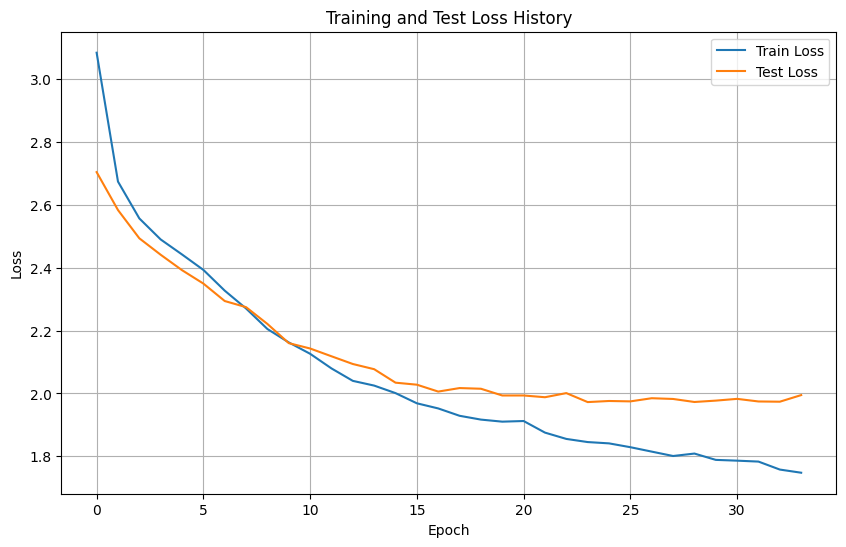

In [36]:
if len(train_loss_history) > 0 and len(test_loss_history) > 0:
    plt.figure(figsize=(10, 6))
    plt.plot(train_loss_history, label='Train Loss')
    plt.plot(test_loss_history, label='Test Loss')
    plt.title('Training and Test Loss History')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("No loss history to plot.")

### Sample Name Generator

# Check if model has been trained
if 'train_loss_history' in locals() and len(train_loss_history) > 0:

In [42]:
    def generate_name(model, start_char='a', max_len=10, temperature=0.8):
        model.eval() # Set model to evaluation mode
        generated_name_indices = []

        # Encode the starting character (or handle empty start string)
        if start_char and start_char in char_to_idx:
            current_sequence = [char_to_idx[start_char]]
        else:
            # If invalid or no start_char, start with a random common character
            # Use the global `unique_chars_for_gen` which contains actual characters and <EOS> but excludes <PAD>
            valid_start_chars = [char for char in unique_chars_for_gen if char != '<EOS>']
            if not valid_start_chars: # Fallback if all chars are excluded
                current_sequence = [char_to_idx['a']]
            else:
                current_sequence = [char_to_idx[random.choice(valid_start_chars)]]

        generated_name_indices.extend(current_sequence)

        with torch.no_grad():
            for _ in range(max_len):
                # Prepare input tensor, padding to max_len if needed
                input_tensor = torch.zeros(1, max_len, dtype=torch.long, device=device)
                seq_len = len(current_sequence)
                # Ensure current_sequence does not exceed max_len for input_tensor
                input_tensor[0, :min(seq_len, max_len)] = torch.tensor(current_sequence[-max_len:], device=device)

                # Get model prediction
                output = model(input_tensor)
                # Take the prediction for the last character in the sequence
                logits = output[0, :]  # This should be the logits for the last time step

                # Apply temperature for sampling
                if temperature == 0:
                    probabilities = torch.softmax(logits, dim=-1)
                    next_char_idx = torch.argmax(probabilities).item()
                else:
                    probabilities = torch.softmax(logits / temperature, dim=-1)
                    next_char_idx = torch.multinomial(probabilities, 1).item()

                # If <EOS> token is predicted, stop generating
                if next_char_idx in idx_to_char and idx_to_char[next_char_idx] == '<EOS>':
                    break

                generated_name_indices.append(next_char_idx)
                current_sequence.append(next_char_idx)

        # Convert indices back to characters, filtering out <EOS> and padding characters
        generated_chars = []
        for idx in generated_name_indices:
            if idx in idx_to_char and idx_to_char[idx] not in ['<EOS>', '<PAD>']:
                generated_chars.append(idx_to_char[idx])

        generated_name = ''.join(generated_chars)
        return generated_name

    # Generate some names
    print("Generated Names (starting with 'a'):")
    print("---------------------------------")
    for _ in range(5):
        print(generate_name(model, start_char='a', max_len=10))

    print("\nGenerated Names (starting with 'r'):")
    print("---------------------------------")
    for _ in range(5):
        print(generate_name(model, start_char='r', max_len=7))

    print("\nGenerated Names (random start):")
    print("-------------------------------")
    for _ in range(5):
        # Use the global `unique_chars_for_gen` for random start characters
        random_start_char = random.choice([char for char in unique_chars_for_gen if char != '<EOS>'])
        print(generate_name(model, start_char=random_start_char, max_len=5))

Generated Names (starting with 'a'):
---------------------------------
anchan
ashesh
akryana
amiyan
ashitan

Generated Names (starting with 'r'):
---------------------------------
rima
roh
rult
rat
rita

Generated Names (random start):
-------------------------------
nah
chsh
wcrl
man
win
